# Revisió de cobertura OCR i expansió M3Kang

## Resum

`data` ara conté 40.617 files per a 1.747 problemes, amb 108 idiomes disponibles en el conjunt. Cada problema conserva el seu `train` o `val`; les traduccions d'un mateix ID no es reparteixen entre els dos splits. La cobertura per problema és desigual: cada ID té entre 2 i 100 idiomes.

Per a 1.115 IDs, les opcions A–E d'anglès/català coincideixen i s'han compartit amb les traduccions disponibles: 24.963 files de nous idiomes i 60 files EN/CAT que abans eren buides. En 207 IDs l'OCR d'anglès i català discrepa; s'han preservat aquestes opcions originals i no s'han propagat. En 425 IDs no hi havia opcions d'origen.

La cobertura d'opcions mesura quantes files tenen A–E completes, no si la transcripció és correcta. La revisió visual anterior va trobar possibles errors en valors numèrics; cal revisar especialment fraccions, exponents i expressions amb diversos tokens.

## Context i mètode

- Grain: una fila per `(id, language)`; cada problema inclou anglès i català, a més de les altres traduccions disponibles.
- Opcions completes: A–E presents i no buides. `{}` compta com a absència; opcions gràfiques poden ser absència esperada.
- Les opcions només es comparteixen quan les fonts EN/CAT coincideixen després de normalitzar espais i puntuació adjacent. Els 207 conflictes es llisten a `data/ocr_option_conflicts.jsonl`.
- La comparació amb el nostre OCR es limita als mateixos IDs anglesos i al mateix split. Després de l'expansió, la cobertura anglesa inclou també opcions consensuades transferides des del català.
- M3Kang és d'ús per a recerca. Aquest notebook mostra agregats, no preguntes, imatges ni IDs.

Fonts: `data/train.jsonl`, `data/val.jsonl`, `data/ocr_option_conflicts.jsonl`, `data/m3kang_expansion_manifest.json`, `data/.ocr_cache.jsonl`, `data/ocr_fixes.jsonl` i `data_backup_before_company/reviewed/all/{train,val}.jsonl`. Executa des de l'arrel del projecte.


In [1]:
from collections import Counter, defaultdict
from pathlib import Path
import json, math
import matplotlib.pyplot as plt
from IPython.display import Markdown, display

roots = [Path.cwd(), *Path.cwd().parents]
ROOT = next((p for p in roots if (p / "data" / "train.jsonl").is_file()), None)
if ROOT is None:
    raise FileNotFoundError("Run from the project root containing data/train.jsonl")

def read_jsonl(path):
    return [json.loads(line) for line in path.read_text(encoding="utf-8-sig").splitlines() if line.strip()]

def option_count(row):
    options = row.get("options") or {}
    return sum(isinstance(options.get(k), str) and bool(options[k].strip()) for k in "ABCDE")

def complete(row):
    options = row.get("options") or {}
    return set(options) == set("ABCDE") and option_count(row) == 5

def rate(n, total):
    return 100 * n / total if total else math.nan

def table(headers, rows):
    lines = ["| " + " | ".join(headers) + " |", "| " + " | ".join("---" for _ in headers) + " |"]
    lines += ["| " + " | ".join(str(x).replace("|", r"\|") for x in row) + " |" for row in rows]
    display(Markdown("\n".join(lines)))

company = {s: read_jsonl(ROOT / "data" / f"{s}.jsonl") for s in ("train", "val")}
reviewed = {s: read_jsonl(ROOT / "data_backup_before_company" / "reviewed" / "all" / f"{s}.jsonl") for s in ("train", "val")}
print(f"M3Kang actual: {sum(map(len,company.values())):,} files; OCR revisat anterior: {sum(map(len,reviewed.values())):,} files")


M3Kang actual: 40,617 files; OCR revisat anterior: 1,411 files


### 1. Completeness and grain

In [2]:
company_ids = {}
for split, rows in company.items():
    keys = [(r.get("id"), r.get("language")) for r in rows]
    assert len(keys) == len(set(keys)), f"Duplicate (id, language) in {split}"
    assert all(r.get("label") in set("ABCDE") for r in rows), f"Invalid label in {split}"
    assert all(option_count(r) in (0, 5) for r in rows), f"Partial options in {split}"
    grouped = defaultdict(set)
    grouped_rows = defaultdict(list)
    for r in rows:
        grouped[r["id"]].add(r["language"])
        grouped_rows[r["id"]].append(r)
    assert all({"eng", "cat"} <= langs for langs in grouped.values())
    assert all(len({(r.get("label"), r.get("text_only")) for r in group}) == 1
               for group in grouped_rows.values())
    company_ids[split] = set(grouped)
assert not (company_ids["train"] & company_ids["val"]), "Train/val overlap"

all_company = [r for split in company for r in company[split]]
by_id = defaultdict(list)
for row in all_company:
    by_id[row["id"]].append(row)
manifest = json.loads((ROOT / "data" / "m3kang_expansion_manifest.json").read_text(encoding="utf-8"))
conflicts = read_jsonl(ROOT / "data" / "ocr_option_conflicts.jsonl")
conflict_ids = {r["id"] for r in conflicts}
assert len(all_company) == manifest["rows_total"] == 40617
assert len(by_id) == manifest["unique_problems"] == 1747
assert len({r["language"] for r in all_company}) == len(manifest["languages"]) == 108
assert len(conflict_ids) == manifest["problem_ids_with_option_conflicts"] == 207
for conflict in conflicts:
    group = {r["language"]: r for r in by_id[conflict["id"]]}
    for lang, options in conflict["options_by_language"].items():
        assert group[lang].get("options") == options
    assert all(not row.get("options") for lang, row in group.items() if lang not in {"eng", "cat"})
for problem_id, group in by_id.items():
    if problem_id not in conflict_ids:
        options = [r.get("options") or {} for r in group if complete(r)]
        assert not options or all(option == options[0] for option in options), problem_id
no_options_ids = {problem_id for problem_id, group in by_id.items()
                  if not any(complete(row) for row in group)}
assert len(no_options_ids) == manifest["problem_ids_without_source_options"] == 425

profile = []
for split, rows in company.items():
    for lang in ("eng", "cat"):
        group = [r for r in rows if r["language"] == lang]
        text = [r for r in group if r.get("text_only") is True]
        visual = [r for r in group if r.get("text_only") is False]
        a, t, v = sum(map(complete, group)), sum(map(complete, text)), sum(map(complete, visual))
        profile.append((split, lang, len(group), f"{a}/{len(group)} ({rate(a,len(group)):.1f}%)", len(group)-a,
                        f"{t}/{len(text)} ({rate(t,len(text)):.1f}%)", f"{v}/{len(visual)} ({rate(v,len(visual)):.1f}%)"))
table(["Split", "Idioma", "Preguntes", "Opcions A–E", "Buides", "Text only", "Text amb figura"], profile)

for lang in ("eng", "cat"):
    group = [r for r in all_company if r["language"] == lang]
    print(f"{lang}: {len(group)} files; {sum(complete(r) for r in group)} amb opcions completes; "
          f"text_only {sum(r.get('text_only') is True and complete(r) for r in group)}/"
          f"{sum(r.get('text_only') is True for r in group)}")
coverage = Counter(len(group) for group in by_id.values())
print(f"Grain: {len(all_company):,} claus úniques (id, language); {len(by_id):,} problemes; "
      f"{len({r['language'] for r in all_company})} idiomes; {min(coverage)}–{max(coverage)} idiomes per problema")
print(f"Opcions: {sum(map(complete, all_company)):,} files completes; {len(conflict_ids)} conflictes sense propagar; "
      f"{len(no_options_ids)} IDs sense opcions d'origen")
print("Imatges d'origen EN/CAT:", len(list((ROOT / "data" / "images").glob("*.png"))))


| Split | Idioma | Preguntes | Opcions A–E | Buides | Text only | Text amb figura |
| --- | --- | --- | --- | --- | --- | --- |
| train | eng | 1466 | 1113/1466 (75.9%) | 353 | 684/688 (99.4%) | 429/778 (55.1%) |
| train | cat | 1466 | 1113/1466 (75.9%) | 353 | 684/688 (99.4%) | 429/778 (55.1%) |
| val | eng | 281 | 209/281 (74.4%) | 72 | 121/123 (98.4%) | 88/158 (55.7%) |
| val | cat | 281 | 209/281 (74.4%) | 72 | 121/123 (98.4%) | 88/158 (55.7%) |

eng: 1747 files; 1322 amb opcions completes; text_only 805/811
cat: 1747 files; 1322 amb opcions completes; text_only 805/811
Grain: 40,617 claus úniques (id, language); 1,747 problemes; 108 idiomes; 2–100 idiomes per problema
Opcions: 27,607 files completes; 207 conflictes sense propagar; 425 IDs sense opcions d'origen
Imatges d'origen EN/CAT: 3494


### 2. Same-question comparison with current OCR

In [3]:
compare = {}
comparison_rows = []
for split in ("train", "val"):
    c = {r["id"]: r for r in company[split] if r.get("language") == "eng"}
    o = {r["id"]: r for r in reviewed[split] if r.get("language") == "eng"}
    common = set(c) & set(o)
    assert all(c[i].get("label") == o[i].get("label") and c[i].get("text") == o[i].get("text")
               and c[i].get("text_only") == o[i].get("text_only") for i in common)
    for cohort, pred in (("Totes", lambda r: True), ("Text only", lambda r: r.get("text_only") is True),
                         ("Text amb figura", lambda r: r.get("text_only") is False)):
        ids = [i for i in common if pred(c[i])]
        old = sum(complete(o[i]) for i in ids)
        new = sum(complete(c[i]) for i in ids)
        recovered = sum(complete(c[i]) and not complete(o[i]) for i in ids)
        both_full_diff = sum(complete(c[i]) and complete(o[i]) and c[i].get("options") != o[i].get("options") for i in ids)
        comparison_rows.append((split, cohort, len(ids), f"{old}/{len(ids)} ({rate(old,len(ids)):.1f}%)",
                                f"{new}/{len(ids)} ({rate(new,len(ids)):.1f}%)", recovered, both_full_diff))
        compare[(split, cohort)] = (len(ids), old, new)
table(["Split", "Cohort", "En comú", "OCR actual", "data", "Recuperades", "Valors diferents ambdós plens"], comparison_rows)
print("English rows in company:", sum(r.get("language") == "eng" for r in all_company))
print("English rows in current reviewed:", sum(r.get("language") == "eng" for s in reviewed for r in reviewed[s]))


| Split | Cohort | En comú | OCR actual | data | Recuperades | Valors diferents ambdós plens |
| --- | --- | --- | --- | --- | --- | --- |
| train | Totes | 1184 | 768/1184 (64.9%) | 958/1184 (80.9%) | 190 | 8 |
| train | Text only | 688 | 514/688 (74.7%) | 684/688 (99.4%) | 170 | 5 |
| train | Text amb figura | 496 | 254/496 (51.2%) | 274/496 (55.2%) | 20 | 3 |
| val | Totes | 227 | 140/227 (61.7%) | 177/227 (78.0%) | 37 | 0 |
| val | Text only | 123 | 87/123 (70.7%) | 121/123 (98.4%) | 34 | 0 |
| val | Text amb figura | 104 | 53/104 (51.0%) | 56/104 (53.8%) | 3 | 0 |

English rows in company: 1747
English rows in current reviewed: 1411


### 3. Retry/cache reconciliation

In [4]:
cache = read_jsonl(ROOT / "data" / ".ocr_cache.jsonl")
fixes = read_jsonl(ROOT / "data" / "ocr_fixes.jsonl")
by_key = defaultdict(list)
for row in cache:
    by_key[row["key"]].append(row)
fix_by_key = {row["key"]: row for row in fixes}
first = {k: rows[0] for k, rows in by_key.items()}
last = {k: rows[-1] for k, rows in by_key.items()}
repeated = {k for k, rows in by_key.items() if len(rows) > 1}
assert repeated == set(fix_by_key)
assert all(len(by_key[k]) == 2 for k in repeated)
assert all(len(by_key[k]) == 1 for k in set(by_key) - repeated)
assert all(not complete(first[k]) and last[k].get("options") == fix_by_key[k].get("options") for k in repeated)
pre, post = sum(map(complete, first.values())), sum(map(complete, last.values()))
table(["Fase", "Claus", "Opcions completes", "Buides", "Cobertura"], [
    ("Primer registre", len(first), pre, len(first)-pre, f"{rate(pre,len(first)):.1f}%"),
    ("Últim registre", len(last), post, len(last)-post, f"{rate(post,len(last)):.1f}%"),
    ("Reintents", len(repeated), len(repeated), 0, f"+{rate(len(repeated),len(first)):.1f} punts"),
])
methods = Counter(r.get("how", "(sense mètode)") for r in fixes)
table(["Mètode", "Registres"], sorted(methods.items()))


| Fase | Claus | Opcions completes | Buides | Cobertura |
| --- | --- | --- | --- | --- |
| Primer registre | 3494 | 2202 | 1292 | 63.0% |
| Últim registre | 3494 | 2584 | 910 | 74.0% |
| Reintents | 382 | 382 | 0 | +10.9 punts |

| Mètode | Registres |
| --- | --- |
| copy:cat | 38 |
| copy:eng | 172 |
| crop0.35x3 | 8 |
| crop0.5x2 | 147 |
| crop0.5x3 | 8 |
| crop0.7x2 | 2 |
| crop1.0x2 | 7 |

### 4. Coverage chart

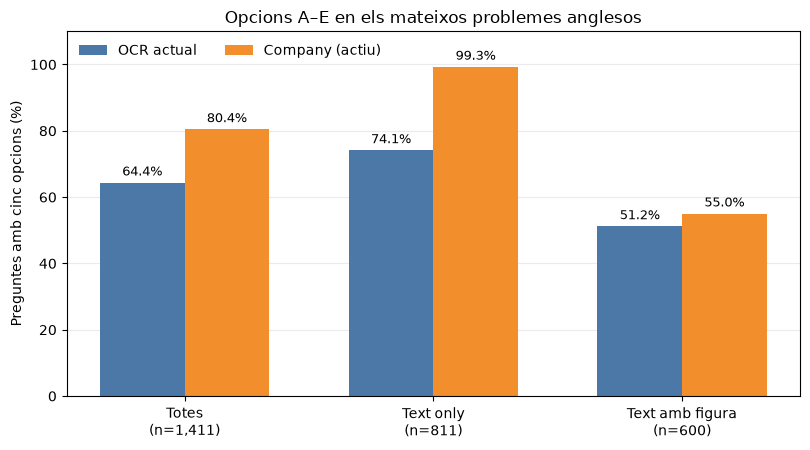

In [5]:
cohorts = ["Totes", "Text only", "Text amb figura"]
old_rates, new_rates, sizes = [], [], []
for cohort in cohorts:
    parts = [compare[(s, cohort)] for s in ("train", "val")]
    n = sum(x[0] for x in parts)
    sizes.append(n)
    old_rates.append(100 * sum(x[1] for x in parts) / n)
    new_rates.append(100 * sum(x[2] for x in parts) / n)

fig, ax = plt.subplots(figsize=(8.2, 4.6))
x = list(range(len(cohorts)))
w = 0.34
b1 = ax.bar([i-w/2 for i in x], old_rates, w, label="OCR actual", color="#4C78A8")
b2 = ax.bar([i+w/2 for i in x], new_rates, w, label="Company (actiu)", color="#F28E2B")
ax.set_title("Opcions A–E en els mateixos problemes anglesos")
ax.set_ylabel("Preguntes amb cinc opcions (%)")
ax.set_xticks(x, [f"{label}\n(n={n:,})" for label, n in zip(cohorts, sizes)])
ax.set_ylim(0, 110)
ax.grid(axis="y", alpha=.25)
ax.set_axisbelow(True)
ax.legend(frameon=False, ncols=2, loc="upper left")
ax.bar_label(b1, fmt="%.1f%%", padding=3, fontsize=9)
ax.bar_label(b2, fmt="%.1f%%", padding=3, fontsize=9)
fig.tight_layout()
plt.show()


## Conclusions i límits

- La base ampliada té 40.617 claus úniques `(id, language)`, 1.747 problemes i 108 idiomes. Tots els IDs apareixen a anglès i català; altres idiomes només són presents quan M3Kang els proporciona. No hi ha duplicats ni solapament entre `train` i `val`, i les traduccions d'un problema mantenen el mateix `label` i `text_only`.
- Hi ha 1.115 IDs amb opcions consensuades, 207 amb discrepàncies EN/CAT i 425 sense opcions d'origen. Els conflictes i la cobertura es verifiquen al bloc 1; les opcions discrepants no s'han endevinat ni propagat.
- Les opcions A–E completes indiquen cobertura, no exactitud. La mostra visual anterior és petita i no permet estimar la precisió general de l'OCR. La transferència entre idiomes pot reproduir errors que les fonts comparteixin.
- El cache té 382 claus amb reintents: les opcions inicials eren buides i l'últim registre es va omplir. 172 correccions usen crops; 210 copien opcions de l'altre idioma.
- Aquest notebook no executa inferència del model ni reporta la seva exactitud. Per avaluar raonament, s'ha d'utilitzar el split `val` previst.
